In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import ConnectionPatch
import matplotlib.gridspec as gridspec

## Large Human Corpus

In [2]:
df = pd.read_csv('/lustre/scratch126/cellgen/team361/am84/NicheJEPA/results/silver_dataset_statistics.csv')
display(df.head())

num_datasets = df['dataset_id'].nunique()
print(f"Number of Datasets: {num_datasets}")

num_cells = df['n_cells'].sum()
print(f"Number of Cells: {num_cells}")

,dataset_id,dataset_name,adata_batch_path,n_cells,n_genes,assay,species,tissue,batch
0,14,mhb14-1b_1p,/lustre/scratch126/cellgen/team361/DATASETS/si...,689546,498,merfish,homo_sapiens,breast,batch0
1,15,mhc15-2b_1p,/lustre/scratch126/cellgen/team361/DATASETS/si...,649711,498,merfish,homo_sapiens,colon,batch0
2,15,mhc15-2b_1p,/lustre/scratch126/cellgen/team361/DATASETS/si...,779379,498,merfish,homo_sapiens,colon,batch1
3,16,mhl16-2b_1p,/lustre/scratch126/cellgen/team361/DATASETS/si...,582921,498,merfish,homo_sapiens,liver,batch0
4,16,mhl16-2b_1p,/lustre/scratch126/cellgen/team361/DATASETS/si...,531649,498,merfish,homo_sapiens,liver,batch1


Number of Datasets: 49
Number of Cells: 50983495


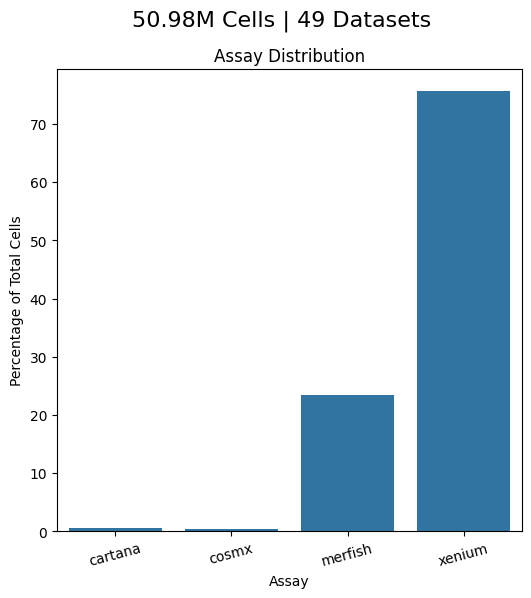

In [4]:
def simple_assay_bar_plot(
    num_cells,
    num_datasets,
    df
):
    fig, ax = plt.subplots(1, 1, figsize=(6, 6))
    assay_counts = df.groupby("assay")['n_cells'].sum().reset_index()
    assay_counts['percentage'] = (assay_counts['n_cells'] / num_cells) * 100

    sns.barplot(data=assay_counts, x="assay", y="percentage", ax=ax)
    ax.set_title("Assay Distribution")
    ax.set_xlabel('Assay')
    ax.set_ylabel('Percentage of Total Cells')
    ax.tick_params(axis='x', rotation=15)

    plt.suptitle(f"{num_cells/1e6:.2f}M Cells | {num_datasets} Datasets", fontsize=16)
    plt.show()
    
simple_assay_bar_plot(num_cells, num_datasets, df)

/tmp/ipykernel_457571/788488110.py:15: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=tissue_counts, x="tissue", y="percentage", palette=colors, ax=ax)


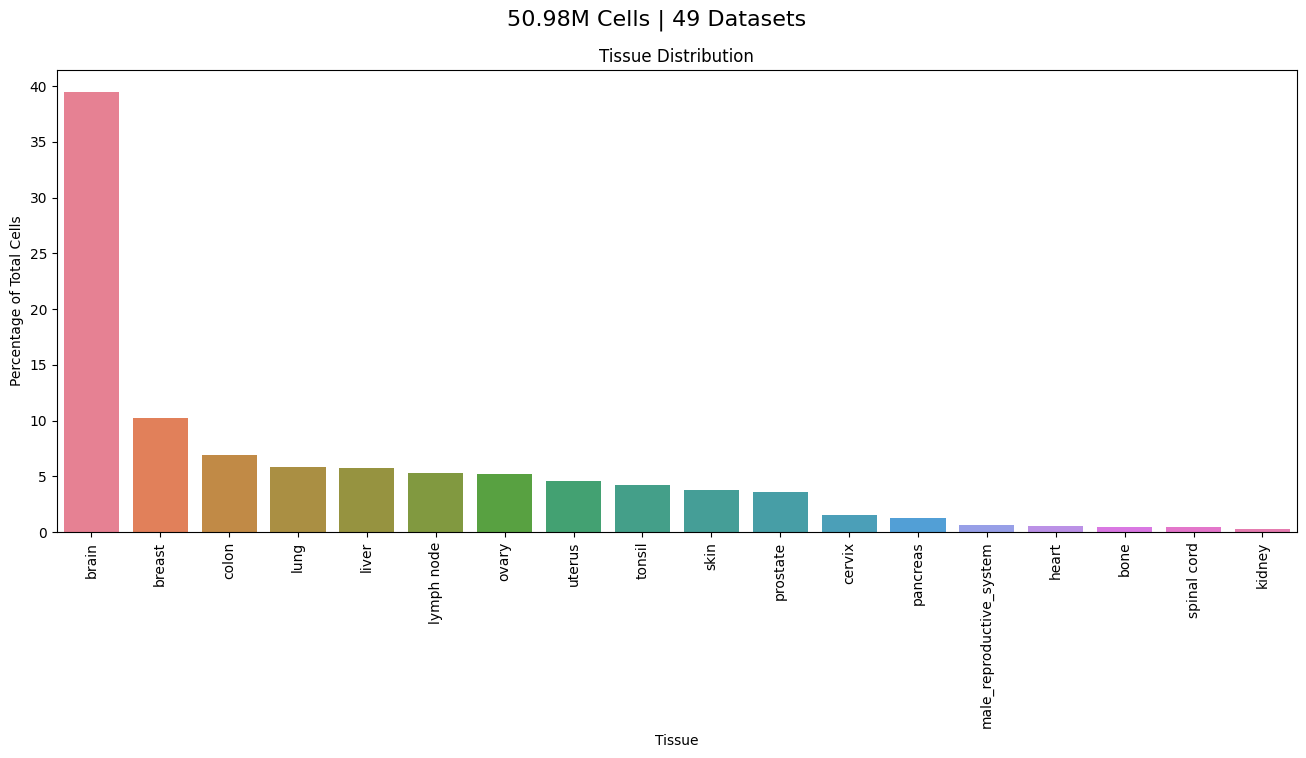

In [22]:
def simple_tissue_bar_plot(
    num_cells,
    num_datasets,
    df
):
    fig, ax = plt.subplots(1, 1, figsize=(16, 6))

    # fig, ax = plt.subplots(1, 1, figsize=(4, 16))

    tissue_counts = df.groupby("tissue")['n_cells'].sum().reset_index()
    tissue_counts['percentage'] = (tissue_counts['n_cells'] / num_cells) * 100
    tissue_counts = tissue_counts.sort_values(by='percentage', ascending=False)

    colors = sns.color_palette('husl', len(tissue_counts))
    sns.barplot(data=tissue_counts, x="tissue", y="percentage", palette=colors, ax=ax)
    # sns.barplot(data=tissue_counts, y="tissue", x="percentage", palette=colors, ax=ax)

    ax.set_title("Tissue Distribution")

    ax.set_xlabel('Tissue')
    ax.set_ylabel('Percentage of Total Cells')
    ax.tick_params(axis='x', rotation=90)

    # ax.set_ylabel('Tissue')
    # ax.set_xlabel('Percentage of Total Cells')
    # ax.tick_params(axis='y', rotation=15)

    plt.suptitle(f"{num_cells/1e6:.2f}M Cells | {num_datasets} Datasets", fontsize=16)
    plt.show()
    
simple_tissue_bar_plot(num_cells, num_datasets, df)

## 30M Corpus Summary Statistics Visualization

In [2]:
df = pd.read_csv("/lustre/scratch126/cellgen/team361/am84/NicheJEPA/results/silver_statistics/full_statistics.csv")
print(df.shape)
display(df.head())

(723, 13)


,top_level_folder,dataset_folder,dataset_file,n_cells,n_genes,assay,species,tissue,disease_level1,disease_level2,disease_level3,sex,age_group
0,/lustre/scratch126/cellgen/team361/bc8/cytowea...,"['MERSCOPE_Human_Breast_Cancer_Patient1\n', 'M...",harmonised_adata.h5ad,689010,497,merfish,homo_sapiens,breast,cancer,breast_cancer,breast_cancer,na,NaN
1,/lustre/scratch126/cellgen/team361/bc8/cytowea...,"['MERSCOPE_Human_Breast_Cancer_Patient1\n', 'M...",harmonised_adata.h5ad,649301,497,merfish,homo_sapiens,colon,cancer,colon_cancer,colon_cancer,na,NaN
2,/lustre/scratch126/cellgen/team361/bc8/cytowea...,"['MERSCOPE_Human_Breast_Cancer_Patient1\n', 'M...",harmonised_adata.h5ad,778495,497,merfish,homo_sapiens,colon,cancer,colon_cancer,colon_cancer,na,NaN
3,/lustre/scratch126/cellgen/team361/bc8/cytowea...,"['MERSCOPE_Human_Breast_Cancer_Patient1\n', 'M...",harmonised_adata.h5ad,531414,497,merfish,homo_sapiens,liver,cancer,liver_cancer,liver_cancer,na,NaN
4,/lustre/scratch126/cellgen/team361/bc8/cytowea...,"['MERSCOPE_Human_Breast_Cancer_Patient1\n', 'M...",harmonised_adata.h5ad,582785,497,merfish,homo_sapiens,liver,cancer,liver_cancer,liver_cancer,na,NaN


In [3]:
total_cells = df['n_cells'].sum()
print(f"Total number of cells: {total_cells}")

df_mouse = df[df['species'] == 'mus_musculus']
mouse_cells = df_mouse['n_cells'].sum()
print(f"Number of mouse cells: {mouse_cells}")
print(f"Number of human cells: {total_cells - mouse_cells}")


Total number of cells: 76785610
Number of mouse cells: 14116020
Number of human cells: 62669590


In [4]:
df1 = df[df['dataset_folder'] == 'xhb1002-76b_1p']
df1

,top_level_folder,dataset_folder,dataset_file,n_cells,n_genes,assay,species,tissue,disease_level1,disease_level2,disease_level3,sex,age_group
648,/lustre/scratch126/cellgen/team361/DATASETS/si...,xhb1002-76b_1p,AT12-BRA-4-FO-1__filt_cells_filt_genes_raw_log...,269462,312,xenium,homo_sapiens,brain,multiple_sclerosis,NaN,NaN,NaN,NaN
649,/lustre/scratch126/cellgen/team361/DATASETS/si...,xhb1002-76b_1p,AT101-BRA-6-FO-5-S7-II__filt_cells_filt_genes_...,52482,341,xenium,homo_sapiens,brain,multiple_sclerosis,NaN,NaN,NaN,NaN
650,/lustre/scratch126/cellgen/team361/DATASETS/si...,xhb1002-76b_1p,AT101-FO5__filt_cells_filt_genes_raw_log1pnorm...,55281,312,xenium,homo_sapiens,brain,multiple_sclerosis,NaN,NaN,NaN,NaN
651,/lustre/scratch126/cellgen/team361/DATASETS/si...,xhb1002-76b_1p,AT9-BRA-4-FO-2-S38__filt_cells_filt_genes_raw_...,243416,341,xenium,homo_sapiens,brain,multiple_sclerosis,NaN,NaN,NaN,NaN
652,/lustre/scratch126/cellgen/team361/DATASETS/si...,xhb1002-76b_1p,AT15-BRA-4-FO-G1-S29__filt_cells_filt_genes_ra...,261495,4949,xenium,homo_sapiens,brain,multiple_sclerosis,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...
718,/lustre/scratch126/cellgen/team361/DATASETS/si...,xhb1002-76b_1p,AT21-BRA-3-FO-1A1-S31-i__filt_cells_filt_genes...,156082,341,xenium,homo_sapiens,brain,multiple_sclerosis,NaN,NaN,NaN,NaN
719,/lustre/scratch126/cellgen/team361/DATASETS/si...,xhb1002-76b_1p,AT3-BRA-5-FO-3-S46__filt_cells_filt_genes_raw_...,144440,341,xenium,homo_sapiens,brain,multiple_sclerosis,NaN,NaN,NaN,NaN
720,/lustre/scratch126/cellgen/team361/DATASETS/si...,xhb1002-76b_1p,AT23-BRA-3-FO-1F2-1__filt_cells_filt_genes_raw...,225243,341,xenium,homo_sapiens,brain,multiple_sclerosis,NaN,NaN,NaN,NaN
721,/lustre/scratch126/cellgen/team361/DATASETS/si...,xhb1002-76b_1p,AT14-BRA-4-FO-2__filt_cells_filt_genes_raw_log...,164441,312,xenium,homo_sapiens,brain,multiple_sclerosis,NaN,NaN,NaN,NaN


In [5]:
df1['n_cells'] = df1['n_cells'].astype(int)
print(df1['n_cells'].sum())

19012868


/tmp/ipykernel_2683493/1867761143.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df1['n_cells'] = df1['n_cells'].astype(int)


In [8]:
df1['n_genes'].value_counts()

n_genes
341     33
312     32
4949    10
Name: count, dtype: int64

In [7]:
def plot_assay_sex_condition_species(df):
    fig, ax = plt.subplots(1,4, figsize=(24, 5))
    cols = ['assay', 'sex', 'disease_level1', 'species']
    colnames = ['Assay', 'Sex', 'Condition', 'Species']
    for i in range(4):
        col_counts = df.groupby(cols[i])['n_cells'].sum().reset_index()

        total_cells = col_counts['n_cells'].sum()
        col_counts['percentage'] = (col_counts['n_cells'] / total_cells) * 100

        sns.barplot(data=col_counts, x=cols[i], y='percentage', ax=ax[i])
        ax[i].set_title(f"{colnames[i]}")
        ax[i].set_xlabel('')
        ax[i].set_ylabel('Percentage of Total Cells')
        ax[i].tick_params(axis='x', rotation=15)

    plt.suptitle(f"Total Cells: {total_cells/1e6:.2f} million", fontsize=16)
    plt.show()

In [13]:
def plot_tissue(df, species='homo_sapiens'):

    # Group by tissue and sum the number of cells
    df.columns = df.columns.str.capitalize()
    tissue_counts = df.groupby('Tissue')['N_cells'].sum().rename('Cells')
    tissue_counts = tissue_counts.sort_values(ascending=False)
    tissue_counts = tissue_counts.rename(index=lambda x: x.replace('_', ' ').capitalize())

    tissues = [str(s) for s in tissue_counts.index.tolist()]
    tissue_counts = tissue_counts.to_list()
    n_cells = sum(tissue_counts)
    ratios = [c/n_cells for c in tissue_counts]

    others_idx = next((i for i, ratio in enumerate(ratios) if ratio < 0.05), len(ratios)) - 1
    print(others_idx)
    
    tissue_categories = tissues[:-others_idx] + ['Others']
    tissue_category_counts = tissue_counts[:-others_idx] + [sum(tissue_counts[-others_idx:])]
    print(tissue_categories)
    print(tissue_category_counts)

    other_tissues = tissues[-others_idx:]
    other_ratios = ratios[-others_idx:]
    
    # make figure and assign axis objects
    font_size = 14
    plt.rcParams['font.size'] = font_size
    fig = plt.figure(figsize=(9, 9))
    gs = gridspec.GridSpec(2, 3, height_ratios=[1, 1], width_ratios=[1, 4, 1])
    ax1 = fig.add_subplot(gs[0, :])  # Pie chart occupies the top two columns
    ax2 = fig.add_subplot(gs[1, 1])  # Bar chart occupies the bottom-right column
    fig.subplots_adjust(wspace=0)
    fig.subplots_adjust(hspace=-0.3)  # Reduce vertical spacing

    # pie chart parameters
    angle = -67.5
    explode = [int(s=='Others')/10 + 0.02 for s in tissue_categories]
    # Set color palette for pie chart
    colors = sns.color_palette('Paired', len(tissue_categories))
    colors = colors[2:] + colors[:2]
    print(colors[0] == colors[-1])
    print(len(colors), len(tissue_categories), len(tissue_category_counts))
    ax1.set_prop_cycle('color', colors)
    wedges, *_ = ax1.pie(tissue_category_counts, autopct='%1.1f%%', startangle=angle,
                        labels=tissue_categories, explode=explode)
    # use ConnectionPatch to draw lines between the two plots
    theta1, theta2 = wedges[-1].theta1, wedges[-1].theta2
    center, r = wedges[-1].center, wedges[-1].r    

    # Horizontal bar chart parameters
    left = 0  # Starting point for horizontal bars
    bar_height = .2  # Thickness of each bar

    # Adding from the left matches the legend
    bar_width = 0.0
    below_2_bars = []  # To keep track of bars with ratios < 2%
    below_2_bars_width = 0  # Combined width for bars < 2%
    for j, (ratio, label) in enumerate(reversed([*zip(other_ratios, other_tissues)])):
        width = ratio / 10
        print(width, ratio)
        bar = ax2.barh(0, width, bar_height, left=left, color=colors[-1], label=label, alpha=0.1 + 0.1 * j)
        label_type = 'center'
        if ratio > 0.02:
            ax2.bar_label(bar, labels=[f"{ratio:.1%}"], label_type=label_type)
        else:
            # place just one text label for all labels below 2% in the middle their bars combined
            below_2_bars.append(bar)  # Add bars < 2% to a separate list
            below_2_bars_width += width
            
        left += width
        bar_width += width

    # Add a single label "< 2%" for all bars less than 2%
    if below_2_bars:
        ax2.text(below_2_bars_width / 2, bar_height / 2 - 0.1, "< 2%", ha='center', va='center', color='black', fontsize=font_size)        

    # Update ax2 aesthetics for horizontal layout
    ax2.legend()
    ax2.axis('off')
    ax2.set_ylim(-2.5 * bar_height, 2.5 * bar_height)

    # Add the legend below the bar plot
    ax2.legend(
        loc="upper center",
        bbox_to_anchor=(0.5, 0.4),
        ncol=2,
        frameon=False
    )

    # Top-left connection line (to left edge of the bar plot)
    x = r * np.cos(np.pi / 180 * theta1) + center[0]
    y = r * np.sin(np.pi / 180 * theta1) + center[1]
    con = ConnectionPatch(xyA=(0, 0.1), coordsA=ax2.transData,
                        xyB=(x, y), coordsB=ax1.transData)
    con.set_color([0, 0, 0])
    con.set_linewidth(1)
    ax2.add_artist(con)

    # Top-right connection line (to right edge of the bar plot)
    x = r * np.cos(np.pi / 180 * theta2) + center[0]
    y = r * np.sin(np.pi / 180 * theta2) + center[1]
    con = ConnectionPatch(xyA=(bar_width, 0.1), coordsA=ax2.transData,
                        xyB=(x, y), coordsB=ax1.transData)
    con.set_color([0, 0, 0])
    con.set_linewidth(1)
    ax2.add_artist(con)

    # plt.suptitle(f"Percentage of Cells by Tissue | Species: {species} | Total Cells: {n_cells/1e6:.1f} million")
    plt.savefig(f"tissue_distribution_{species}.png", bbox_inches='tight', dpi=300)

8
['Breast', 'Colon', 'Lung', 'Ovary', 'Uterus', 'Liver', 'Tonsil', 'Prostate', 'Caudate', 'Skin', 'Others']
[4839630, 4409617, 3196390, 2670561, 2328285, 2310761, 2144625, 1836565, 1578477, 1556616, 4285692]
False
11 11 11
7.99140642173488e-05 0.0007991406421734879
0.0004688223297464386 0.004688223297464386
0.0007743213539051736 0.007743213539051736
0.0007756372608222833 0.0077563726082228324
0.0021458782954922903 0.021458782954922904
0.002498788483015766 0.02498788483015766
0.0034417160273514783 0.03441716027351478
0.003569975227891809 0.03569975227891809


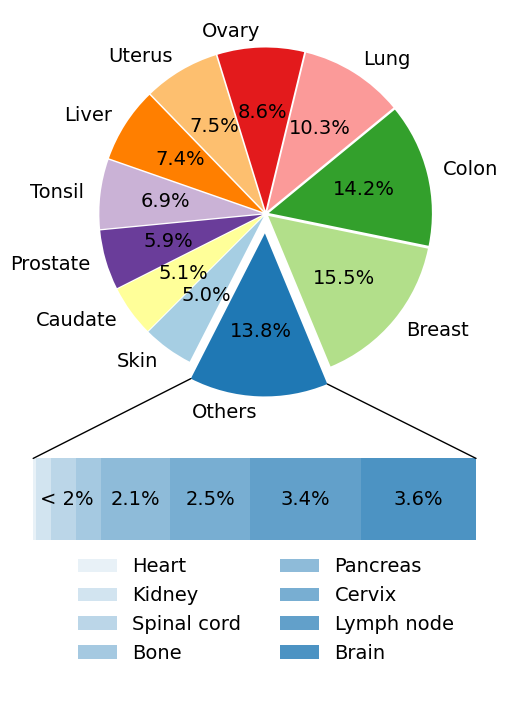

In [14]:
# Plot select df for species as homo_sapiens
species = 'homo_sapiens'
df_human = df[df['species'] == species]
# plot_assay_sex_condition_species(df_human)
plot_tissue(df_human, species=species)

In [69]:
# tissue_counts = tissue_counts.rename(index=lambda x: x.replace('_', ' ').capitalize())

# display(df_human)

print(tissue_counts)
counts = tissue_counts.to_list()
print(counts)

Tissue
Breast         4839630
Colon          4409617
Lung           3196390
Ovary          2670561
Uterus         2328285
Liver          2310761
Tonsil         2144625
Prostate       1836565
Caudate        1578477
Skin           1556616
Brain          1112305
Lymph node     1072343
Cervix          778553
Pancreas        668596
Bone            241667
Spinal cord     241257
Kidney          146072
Heart            24899
Name: Cells, dtype: int64
[4839630, 4409617, 3196390, 2670561, 2328285, 2310761, 2144625, 1836565, 1578477, 1556616, 1112305, 1072343, 778553, 668596, 241667, 241257, 146072, 24899]


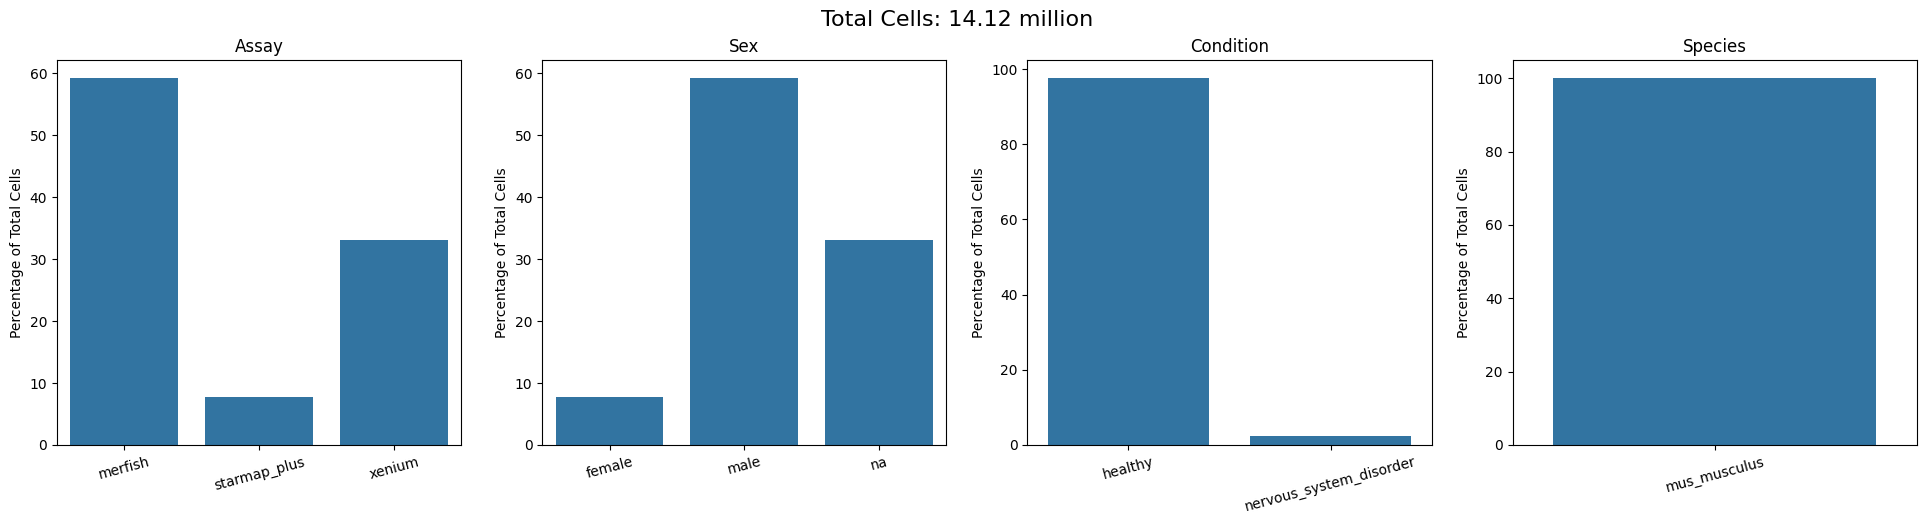

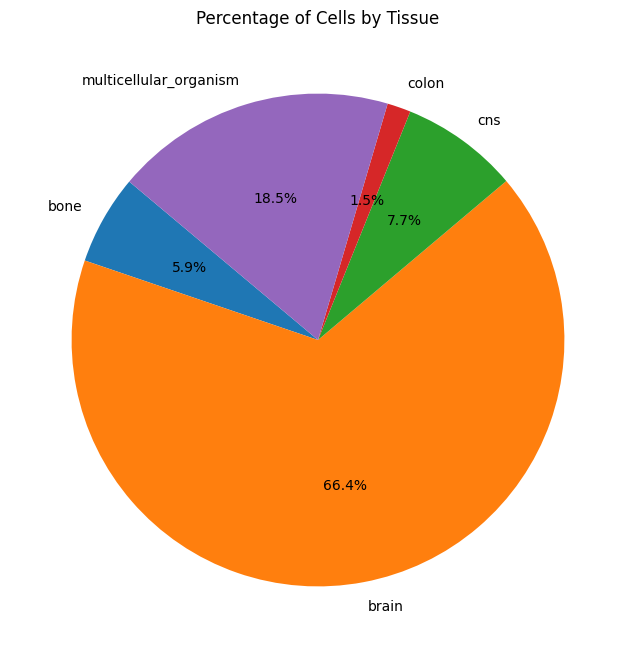

In [10]:
# Plot select df for species as mus_musculus
df_mouse = df[df['species'] == 'mus_musculus']
plot_assay_sex_condition_species(df_mouse)
plot_tissue(df_mouse)

cns 100.0
multicellular_organism 50.19258352528735
brain 45.83030775126564
liver 43.98881722372215
lung 42.92643145098009
brain 19.56940378021409
bone 16.003578216738415
uterus 12.770301100332826
brain 10.390158187716237
prostate 10.02532771574375
skin 9.061427008480514


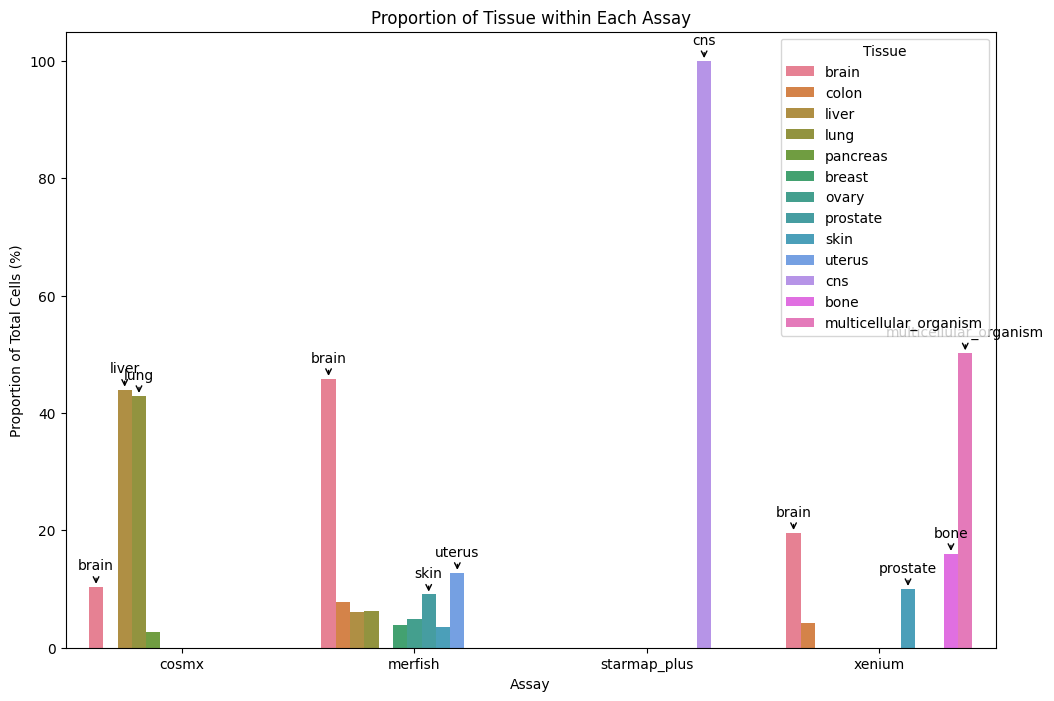

In [18]:
# Group by assay and tissue and sum the number of cells
assay_tissue_counts = df.groupby(['assay', 'tissue'])['n_cells'].sum().reset_index()

# Calculate the total number of cells for each assay
total_cells_per_assay = assay_tissue_counts.groupby('assay')['n_cells'].sum().reset_index()
total_cells_per_assay.columns = ['assay', 'total_cells']

# Merge the total cells per assay back to the assay_tissue_counts
assay_tissue_counts = pd.merge(assay_tissue_counts, total_cells_per_assay, on='assay')

# Calculate the proportion of each tissue within each assay
assay_tissue_counts['proportion'] = (assay_tissue_counts['n_cells'] / assay_tissue_counts['total_cells']) * 100

# Plot bar chart
plt.figure(figsize=(12, 8))
barplot = sns.barplot(data=assay_tissue_counts, x='assay', y='proportion', hue='tissue')
plt.title('Proportion of Tissue within Each Assay')
plt.xlabel('Assay')
plt.ylabel('Proportion of Total Cells (%)')
plt.legend(title='Tissue')

idx_largest = {}
for i in range(len(barplot.patches)):
    bar = barplot.patches[i]
    bar_height = bar.get_height()
    if len(idx_largest) < 11:
        idx_largest[i] = bar_height
    else:
        # Remove item from idx_largest with smallest value
        smallest_value = min(idx_largest.values())
        if bar_height > smallest_value:
            smallest_key = min(idx_largest, key=idx_largest.get)
            del idx_largest[smallest_key]
            idx_largest[i] = bar_height

sorted_idx_largest = sorted(idx_largest, key=idx_largest.get, reverse=True)
names = ['cns', 'multicellular_organism', 'brain', 'liver', 'lung', 'brain', 'bone','uterus', 'brain', 'prostate', 'skin']
assert len(names) == len(sorted_idx_largest)

for i, idx in enumerate(sorted_idx_largest):
    bar = barplot.patches[idx]
    print(names[i], bar.get_height())
    barplot.annotate(
        names[i],
        (bar.get_x() + bar.get_width() / 2, bar.get_height()),
        ha='center',
        va='bottom',
        xytext=(0, 10),  # Offset text position
        textcoords='offset points',
        arrowprops=dict(arrowstyle="->", color='black')
    )

plt.show()